#  Data Cleaning & Preprocessing

This notebook cleans the data and creates datasets for EDA, statistical analysis, and forecasting.

##Import libraries

In [1]:
import pandas as pd
import numpy as np
import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


##Upload dataset

In [2]:
uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


## Extract ZIP file

In [3]:
zip_filename = list(uploaded.keys())[0]

raw_folder = "/content/data/raw"
os.makedirs(raw_folder, exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(raw_folder)

print("Extraction completed!")

Extraction completed!


##  Load datasets

In [4]:
csv_files = {}

for root, dirs, filenames in os.walk(raw_folder):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files[filename.lower()] = os.path.join(root, filename)

orders = pd.read_csv(csv_files["orders.csv"])
customers = pd.read_csv(csv_files["customers.csv"])
products = pd.read_csv(csv_files["products.csv"])
data_dictionary = pd.read_csv(csv_files["data_dictionary.csv"])

print("Datasets loaded successfully.")

Datasets loaded successfully.


##  Create working copies

In [5]:
orders_clean = orders.copy()
customers_clean = customers.copy()
products_clean = products.copy()

print("Working copies created.")

Working copies created.


##  Create data quality report function

In [6]:
def data_quality_report(df, dataset_name):

    report = pd.DataFrame({
        "Column": df.columns,
        "Data_Type": df.dtypes.astype(str).values,
        "Missing_Count": df.isnull().sum().values,
        "Missing_Percentage": (
            df.isnull().sum().values / len(df) * 100
        ),
        "Unique_Values": df.nunique().values
    })

    print(f"\nData Quality Report: {dataset_name}")
    display(report)

    return report

##  Generate data quality reports

In [7]:
orders_quality = data_quality_report(
    orders_clean, "Orders"
)

customers_quality = data_quality_report(
    customers_clean, "Customers"
)

products_quality = data_quality_report(
    products_clean, "Products"
)


Data Quality Report: Orders


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,order_item_id,object,0,0.000000,4352
1,order_id,object,0,0.000000,3200
2,order_date,object,0,0.000000,304
3,customer_id,object,0,0.000000,785
4,product_id,object,0,0.000000,20
5,quantity,int64,0,0.000000,3
6,unit_list_price_gbp,float64,0,0.000000,18
7,discount_pct,int64,0,0.000000,7
8,unit_selling_price_gbp,float64,0,0.000000,115
9,shipping_mode,object,0,0.000000,5



Data Quality Report: Customers


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,customer_id,object,0,0.0,800
1,customer_name,object,0,0.0,530
2,region,object,0,0.0,9
3,is_prime_member,object,0,0.0,2
4,account_created_date,object,0,0.0,623



Data Quality Report: Products


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,product_id,object,0,0.0,20
1,product_name,object,0,0.0,20
2,category,object,0,0.0,6
3,sub_category,object,0,0.0,20
4,brand,object,0,0.0,17
5,unit_cost_gbp,float64,0,0.0,20
6,list_price_gbp,float64,0,0.0,18
7,avg_rating,float64,0,0.0,7
8,review_count,int64,0,0.0,20


##  Save data quality reports

In [8]:
quality_folder = "/content/reports/data_quality"
os.makedirs(quality_folder, exist_ok=True)

orders_quality.to_csv(
    f"{quality_folder}/orders_quality_report.csv",
    index=False
)

customers_quality.to_csv(
    f"{quality_folder}/customers_quality_report.csv",
    index=False
)

products_quality.to_csv(
    f"{quality_folder}/products_quality_report.csv",
    index=False
)

print("Quality reports saved.")

Quality reports saved.


##  Missing values inspection

In [9]:
print("Orders missing values:")
display(orders_clean.isnull().sum())

print("Customers missing values:")
display(customers_clean.isnull().sum())

print("Products missing values:")
display(products_clean.isnull().sum())

Orders missing values:


,0
order_item_id,0
order_id,0
order_date,0
customer_id,0
product_id,0
quantity,0
unit_list_price_gbp,0
discount_pct,0
unit_selling_price_gbp,0
shipping_mode,0


Customers missing values:


,0
customer_id,0
customer_name,0
region,0
is_prime_member,0
account_created_date,0


Products missing values:


,0
product_id,0
product_name,0
category,0
sub_category,0
brand,0
unit_cost_gbp,0
list_price_gbp,0
avg_rating,0
review_count,0


##  Missing value visualization

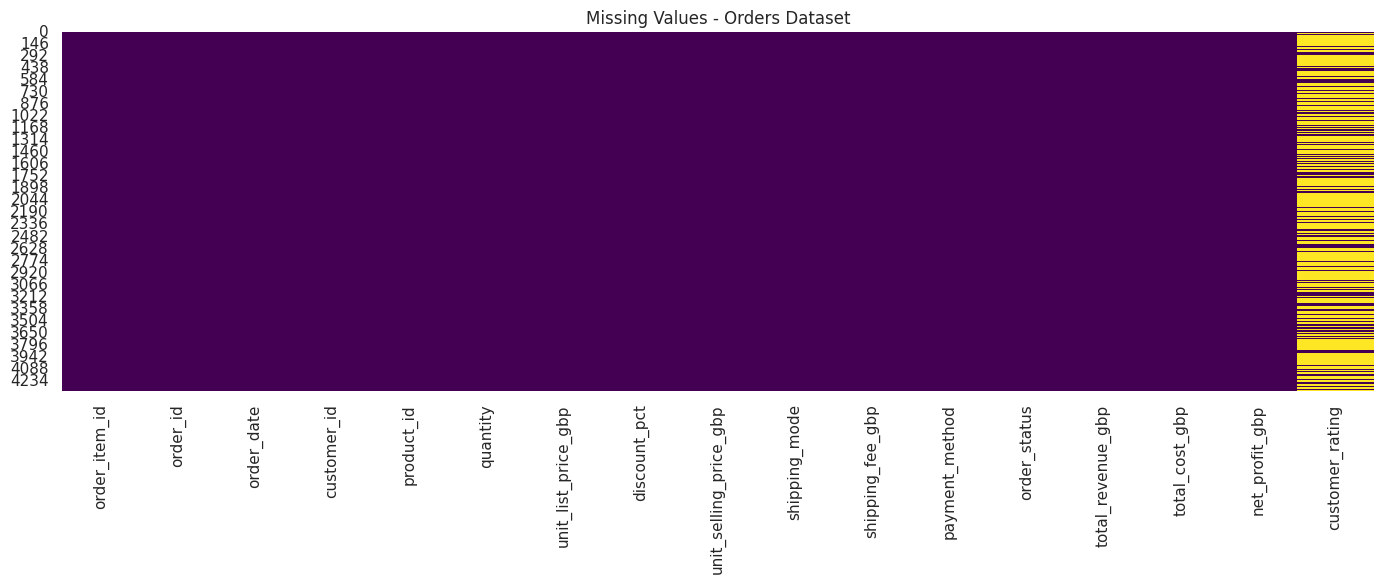

In [10]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    orders_clean.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values - Orders Dataset")
plt.tight_layout()
plt.show()

##  Missing value percentages

In [11]:
missing_summary = pd.DataFrame({
    "Missing_Count": orders_clean.isnull().sum(),
    "Missing_Percentage": (
        orders_clean.isnull().mean() * 100
    )
})

display(
    missing_summary.sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
customer_rating,2956,67.922794
order_item_id,0,0.000000
order_id,0,0.000000
customer_id,0,0.000000
order_date,0,0.000000
quantity,0,0.000000
unit_list_price_gbp,0,0.000000
discount_pct,0,0.000000
product_id,0,0.000000
unit_selling_price_gbp,0,0.000000


##  Remove exact duplicate rows

In [12]:
print("Before removing duplicates:")
print("Orders:", orders_clean.shape)
print("Customers:", customers_clean.shape)
print("Products:", products_clean.shape)

orders_clean = orders_clean.drop_duplicates()
customers_clean = customers_clean.drop_duplicates()
products_clean = products_clean.drop_duplicates()

print("\nAfter removing exact duplicates:")
print("Orders:", orders_clean.shape)
print("Customers:", customers_clean.shape)
print("Products:", products_clean.shape)

Before removing duplicates:
Orders: (4352, 17)
Customers: (800, 5)
Products: (20, 9)

After removing exact duplicates:
Orders: (4352, 17)
Customers: (800, 5)
Products: (20, 9)


##  Convert date columns

In [15]:
orders_clean["order_date"] = pd.to_datetime(
    orders_clean["order_date"],
    errors="coerce"
)

customers_clean["account_created_date"] = pd.to_datetime(
    customers_clean["account_created_date"],
    errors="coerce"
)

print("Date conversion completed.")

Date conversion completed.


##  Check numerical data

In [16]:
numeric_columns = orders_clean.select_dtypes(
    include=np.number
).columns.tolist()

display(orders_clean[numeric_columns].describe())

,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_fee_gbp,total_revenue_gbp,total_cost_gbp,net_profit_gbp,customer_rating
count,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,4352.000000,1396.000000
mean,1.164982,41.278180,3.786765,39.692116,0.952123,47.160657,19.078814,25.971089,4.143983
std,0.433472,34.066458,6.895719,32.987553,1.566700,44.499000,19.378821,25.431105,1.093500
min,1.000000,10.990000,0.000000,7.690000,0.000000,7.690000,4.500000,0.690000,1.000000
25%,1.000000,18.990000,0.000000,18.990000,0.000000,21.980000,8.000000,11.490000,4.000000
50%,1.000000,27.990000,0.000000,27.990000,0.000000,33.240000,12.500000,17.990000,4.000000
75%,1.000000,39.990000,5.000000,39.990000,2.990000,49.990000,22.000000,26.980000,5.000000
max,3.000000,149.000000,30.000000,149.000000,4.990000,447.000000,186.000000,258.500000,5.000000


##  Check quantities

In [17]:
print("Zero quantities:")
print((orders_clean["quantity"] == 0).sum())

print("\nNegative quantities:")
print((orders_clean["quantity"] < 0).sum())

print("\nPositive quantities:")
print((orders_clean["quantity"] > 0).sum())

Zero quantities:
0

Negative quantities:
0

Positive quantities:
4352


##  Check financial values

In [18]:
financial_columns = [
    "unit_list_price_gbp",
    "unit_selling_price_gbp",
    "shipping_fee_gbp",
    "total_revenue_gbp",
    "total_cost_gbp",
    "net_profit_gbp"
]

for column in financial_columns:

    if column in orders_clean.columns:

        print(f"\n{column}")

        print("Negative values:",
              (orders_clean[column] < 0).sum())

        print("Zero values:",
              (orders_clean[column] == 0).sum())


unit_list_price_gbp
Negative values: 0
Zero values: 0

unit_selling_price_gbp
Negative values: 0
Zero values: 0

shipping_fee_gbp
Negative values: 0
Zero values: 3116

total_revenue_gbp
Negative values: 0
Zero values: 0

total_cost_gbp
Negative values: 0
Zero values: 0

net_profit_gbp
Negative values: 0
Zero values: 0


## Inspect discounts

In [19]:
display(orders_clean["discount_pct"].describe())

print("Negative discounts:",
      (orders_clean["discount_pct"] < 0).sum())

print("Discount values:")
display(orders_clean["discount_pct"].value_counts().sort_index())

,discount_pct
count,4352.000000
mean,3.786765
std,6.895719
min,0.000000
25%,0.000000
50%,0.000000
75%,5.000000
max,30.000000


Negative discounts: 0
Discount values:


,count
discount_pct,
0,3053
5,366
10,336
15,299
20,170
25,87
30,41


##  Order status

In [20]:
print("Order status distribution:")
display(orders_clean["order_status"].value_counts(dropna=False))

Order status distribution:


,count
order_status,
Delivered,3895
Returned,372
Cancelled,85


##  Revenue and profit overview

In [21]:
print("Total revenue:",
      orders_clean["total_revenue_gbp"].sum())

print("Total profit:",
      orders_clean["net_profit_gbp"].sum())

print("Unique order IDs:",
      orders_clean["order_id"].nunique())

print("Total records:",
      len(orders_clean))

Total revenue: 205243.18
Total profit: 113026.18000000001
Unique order IDs: 3200
Total records: 4352


##  Outlier visualization

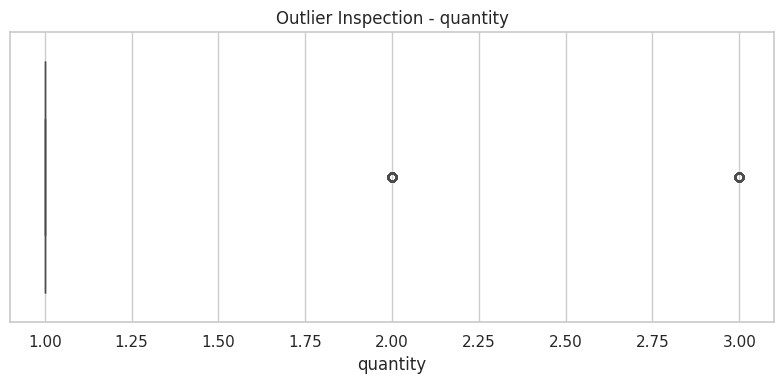

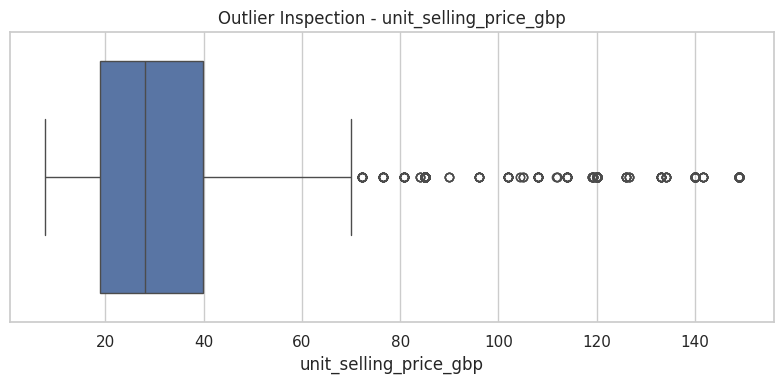

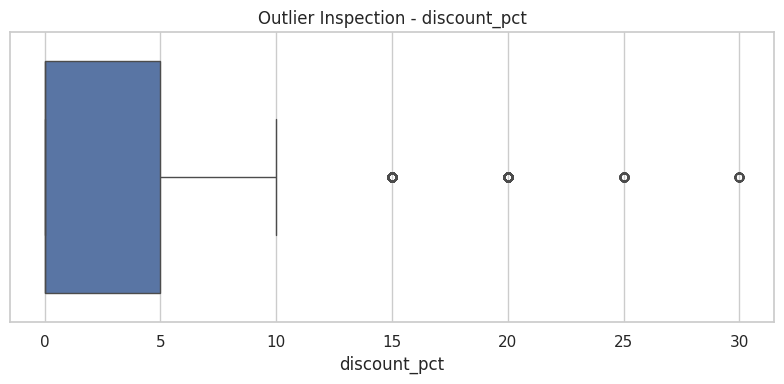

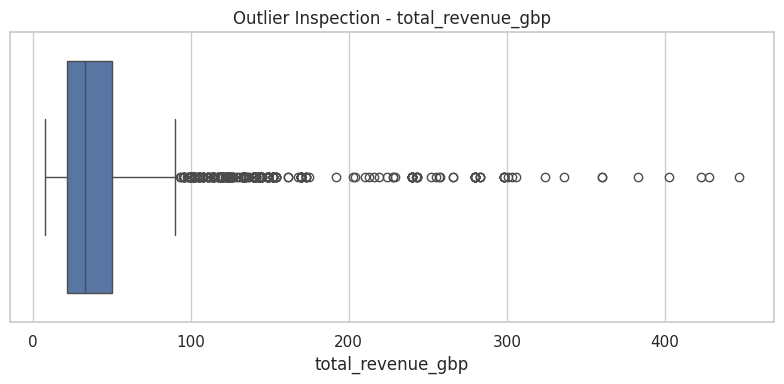

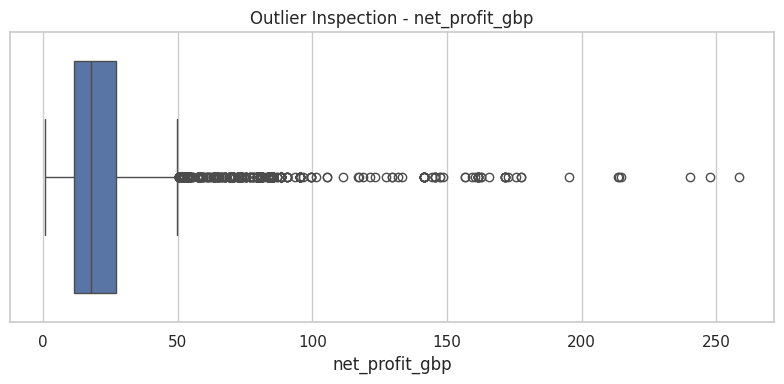

In [22]:
outlier_columns = [
    "quantity",
    "unit_selling_price_gbp",
    "discount_pct",
    "total_revenue_gbp",
    "net_profit_gbp"
]

for column in outlier_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=orders_clean[column])

    plt.title(f"Outlier Inspection - {column}")
    plt.tight_layout()
    plt.show()

##  IQR outlier detection

In [23]:
def detect_outliers_iqr(df, column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Outliers:", len(outliers))
    print("Outlier percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")

    return outliers

for column in outlier_columns:
    detect_outliers_iqr(orders_clean, column)


Column: quantity
Lower bound: 1.0
Upper bound: 1.0
Outliers: 609
Outlier percentage: 13.99 %

Column: unit_selling_price_gbp
Lower bound: -12.510000000000009
Upper bound: 71.49000000000001
Outliers: 599
Outlier percentage: 13.76 %

Column: discount_pct
Lower bound: -7.5
Upper bound: 12.5
Outliers: 597
Outlier percentage: 13.72 %

Column: total_revenue_gbp
Lower bound: -20.035
Upper bound: 92.005
Outliers: 476
Outlier percentage: 10.94 %

Column: net_profit_gbp
Lower bound: -11.745
Upper bound: 50.215
Outliers: 504
Outlier percentage: 11.58 %


This identifies outliers but does not delete them. Unusually large purchases may be legitimate business transactions.

##Check foreign keys

In [24]:
unknown_customers = orders_clean[
    ~orders_clean["customer_id"].isin(
        customers_clean["customer_id"]
    )
]

unknown_products = orders_clean[
    ~orders_clean["product_id"].isin(
        products_clean["product_id"]
    )
]

print("Orders with unknown customers:",
      len(unknown_customers))

print("Orders with unknown products:",
      len(unknown_products))

Orders with unknown customers: 0
Orders with unknown products: 0


## Check duplicate identifiers

In [25]:
print("Duplicate customer IDs:",
      customers_clean["customer_id"].duplicated().sum())

print("Duplicate product IDs:",
      products_clean["product_id"].duplicated().sum())

Duplicate customer IDs: 0
Duplicate product IDs: 0


##  Merge datasets

In [26]:
analysis_data = orders_clean.merge(
    customers_clean,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

analysis_data = analysis_data.merge(
    products_clean,
    on="product_id",
    how="left",
    validate="many_to_one",
    suffixes=("_order", "_product")
)

print("Merged dataset shape:", analysis_data.shape)
display(analysis_data.head())

Merged dataset shape: (4352, 29)


,order_item_id,order_id,order_date,customer_id,product_id,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_mode,...,is_prime_member,account_created_date,product_name,category,sub_category,brand,unit_cost_gbp,list_price_gbp,avg_rating,review_count
0,ITEM-01850,ORD-01353,2026-01-01,C-0455,AMZ-4001,1,21.99,0,21.99,Standard Delivery,...,No,2023-09-24,Non-Slip High-Density Yoga Mat 6mm,Sports & Outdoors,Fitness,ZenFit,8.0,21.99,4.6,1340
1,ITEM-01526,ORD-01112,2026-01-01,C-0237,AMZ-2001,1,84.99,0,84.99,Standard Delivery,...,No,2024-10-01,5.5L Digital Air Fryer Non-Stick Basket,Home & Kitchen,Kitchen Appliances,ChefMate,36.0,84.99,4.7,1640
2,ITEM-01396,ORD-01017,2026-01-01,C-0454,AMZ-1004,1,39.99,0,39.99,Next-Day Express,...,No,2023-06-02,4K Ultra HD Streaming Media Stick,Electronics,TV & Video,AmzBasics Tech,18.0,39.99,4.6,1890
3,ITEM-00371,ORD-00269,2026-01-01,C-0795,AMZ-4002,1,69.99,10,62.99,Standard Delivery,...,No,2025-03-20,Adjustable Dumbbell Pair (2kg - 10kg),Sports & Outdoors,Strength Training,IronGrip,28.0,69.99,4.5,490
4,ITEM-03465,ORD-02546,2026-01-01,C-0075,AMZ-3003,1,10.99,10,9.89,Standard Delivery,...,No,2025-10-30,The Midnight Library (Fiction Paperback),Books,Fiction,Canongate,4.5,10.99,4.5,2900


##  Create date features

In [27]:
analysis_data["year"] = analysis_data["order_date"].dt.year
analysis_data["month"] = analysis_data["order_date"].dt.month
analysis_data["month_name"] = analysis_data["order_date"].dt.month_name()
analysis_data["day"] = analysis_data["order_date"].dt.day
analysis_data["day_name"] = analysis_data["order_date"].dt.day_name()
analysis_data["weekday"] = analysis_data["order_date"].dt.weekday

analysis_data["is_weekend"] = (
    analysis_data["weekday"] >= 5
)

display(analysis_data.head())

,order_item_id,order_id,order_date,customer_id,product_id,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_mode,...,list_price_gbp,avg_rating,review_count,year,month,month_name,day,day_name,weekday,is_weekend
0,ITEM-01850,ORD-01353,2026-01-01,C-0455,AMZ-4001,1,21.99,0,21.99,Standard Delivery,...,21.99,4.6,1340,2026,1,January,1,Thursday,3,False
1,ITEM-01526,ORD-01112,2026-01-01,C-0237,AMZ-2001,1,84.99,0,84.99,Standard Delivery,...,84.99,4.7,1640,2026,1,January,1,Thursday,3,False
2,ITEM-01396,ORD-01017,2026-01-01,C-0454,AMZ-1004,1,39.99,0,39.99,Next-Day Express,...,39.99,4.6,1890,2026,1,January,1,Thursday,3,False
3,ITEM-00371,ORD-00269,2026-01-01,C-0795,AMZ-4002,1,69.99,10,62.99,Standard Delivery,...,69.99,4.5,490,2026,1,January,1,Thursday,3,False
4,ITEM-03465,ORD-02546,2026-01-01,C-0075,AMZ-3003,1,10.99,10,9.89,Standard Delivery,...,10.99,4.5,2900,2026,1,January,1,Thursday,3,False


##  Calculate profit margin

In [28]:
analysis_data["profit_margin_pct"] = np.where(
    analysis_data["total_revenue_gbp"] != 0,
    (
        analysis_data["net_profit_gbp"] /
        analysis_data["total_revenue_gbp"]
    ) * 100,
    np.nan
)

display(analysis_data[
    ["total_revenue_gbp",
     "net_profit_gbp",
     "profit_margin_pct"]
].head())

,total_revenue_gbp,net_profit_gbp,profit_margin_pct
0,24.98,15.48,61.969576
1,87.98,50.48,57.376677
2,44.98,25.48,56.647399
3,65.98,36.48,55.289482
4,12.88,6.88,53.416149


##  Create order-level dataset

In [29]:
order_summary = (
    orders_clean.groupby("order_id")
    .agg(
        order_revenue=("total_revenue_gbp", "sum"),
        order_profit=("net_profit_gbp", "sum"),
        order_date=("order_date", "first"),
        customer_id=("customer_id", "first")
    )
    .reset_index()
)

display(order_summary.head())

print("Total orders:", len(order_summary))
print("Average order value:",
      order_summary["order_revenue"].mean())

,order_id,order_revenue,order_profit,order_date,customer_id
0,ORD-00001,81.46,40.96,2026-02-16,C-0122
1,ORD-00002,89.98,52.48,2026-01-13,C-0627
2,ORD-00003,31.34,16.34,2026-03-10,C-0318
3,ORD-00004,18.99,9.99,2026-03-25,C-0479
4,ORD-00005,17.24,6.24,2026-07-13,C-0663


Total orders: 3200
Average order value: 64.13849375000001


##  Cleaning summary

In [30]:
cleaning_summary = pd.DataFrame({
    "Dataset": ["Orders", "Customers", "Products"],
    "Original_Rows": [
        len(orders),
        len(customers),
        len(products)
    ],
    "Cleaned_Rows": [
        len(orders_clean),
        len(customers_clean),
        len(products_clean)
    ],
    "Rows_Removed": [
        len(orders) - len(orders_clean),
        len(customers) - len(customers_clean),
        len(products) - len(products_clean)
    ]
})

display(cleaning_summary)

,Dataset,Original_Rows,Cleaned_Rows,Rows_Removed
0,Orders,4352,4352,0
1,Customers,800,800,0
2,Products,20,20,0


##  Create folders and save processed data

In [31]:
processed_folder = "/content/data/processed"
figure_folder = "/content/reports/figures/cleaning"

os.makedirs(processed_folder, exist_ok=True)
os.makedirs(figure_folder, exist_ok=True)

orders_clean.to_csv(
    f"{processed_folder}/cleaned_orders.csv",
    index=False
)

customers_clean.to_csv(
    f"{processed_folder}/cleaned_customers.csv",
    index=False
)

products_clean.to_csv(
    f"{processed_folder}/cleaned_products.csv",
    index=False
)

analysis_data.to_csv(
    f"{processed_folder}/cleaned_merged_dataset.csv",
    index=False
)

order_summary.to_csv(
    f"{processed_folder}/order_level_dataset.csv",
    index=False
)

cleaning_summary.to_csv(
    f"{processed_folder}/cleaning_summary.csv",
    index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


##  Download processed dataset

In [32]:
files.download(
    f"{processed_folder}/cleaned_merged_dataset.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##  Download all processed files as ZIP

In [33]:
import shutil

shutil.make_archive(
    "/content/processed_data",
    "zip",
    processed_folder
)

files.download("/content/processed_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>